# K-Nearest Neighbors

Brute-force classifier: for each query point, find the `k` closest training points (Euclidean distance) and vote on the majority label.

## Usage

```python
# (the class is defined in the Implementation section below)

model = KNNClassifier(k=5).fit(X_train, y_train)
preds = model.predict(X_test)
```

This notebook is self-contained: the explanation, the implementation, the visuals, the scikit-learn check and the tests are all here.

## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False})

## Implementation

The whole algorithm, as a plain Python class (numpy only).

In [2]:
from collections import Counter

import numpy as np


class KNNClassifier:
    """Brute-force k-nearest-neighbors classifier (Euclidean distance, majority vote)."""

    def __init__(self, k=5):
        self.k = k
        self.X_train = None
        self.y_train = None

    def fit(self, X, y):
        self.X_train = np.asarray(X, dtype=float)
        self.y_train = np.asarray(y)
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        return np.array([self._predict_one(x) for x in X])

    def _predict_one(self, x):
        dists = np.linalg.norm(self.X_train - x, axis=1)
        k_indices = np.argsort(dists)[: self.k]
        k_labels = self.y_train[k_indices]
        return Counter(k_labels).most_common(1)[0][0]

## See it work

### 1. `k` controls smoothness

kNN has no training: it memorises the data and votes among the `k` nearest points. With `k = 1` the boundary hugs every point (jagged, memorises noise). With a large `k` it becomes smooth, and eventually too smooth (underfits).

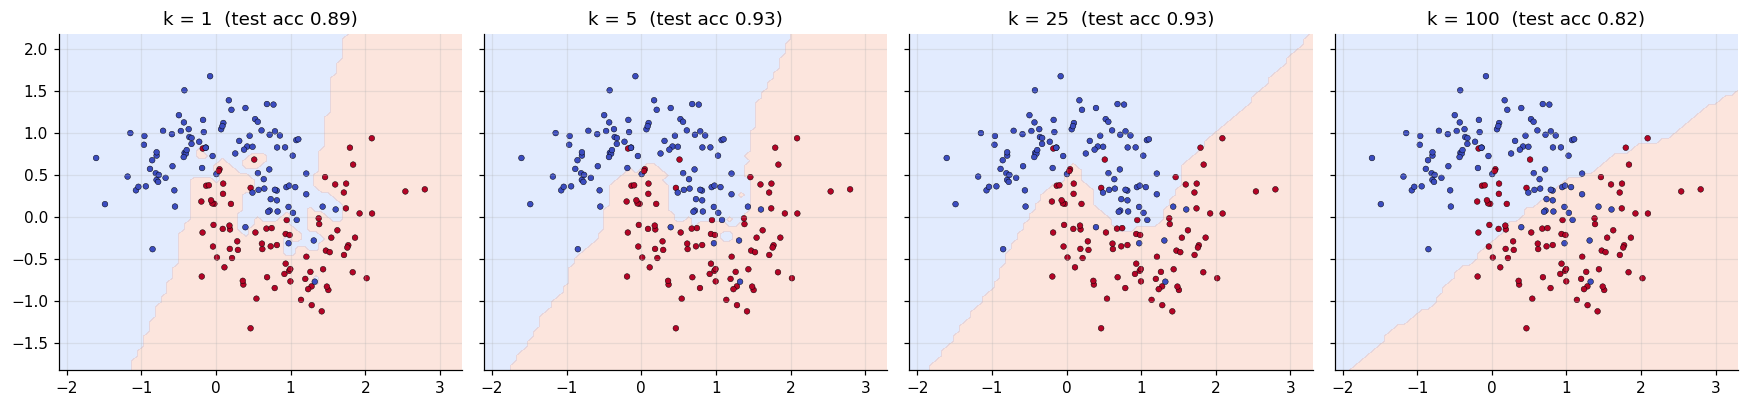

In [3]:
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
def plot_boundary(ax, model, X, y, cmap="coolwarm", n=150, pad=0.5):
    """Colour the plane by the model's predicted class, then draw the data on top."""
    gx, gy = np.meshgrid(np.linspace(X[:, 0].min() - pad, X[:, 0].max() + pad, n), np.linspace(X[:, 1].min() - pad, X[:, 1].max() + pad, n))
    pred = np.asarray(model.predict(np.c_[gx.ravel(), gy.ravel()])).reshape(gx.shape)
    K = len(np.unique(y))
    ax.contourf(gx, gy, pred, alpha=0.25, cmap=cmap, levels=np.arange(-0.5, K + 0.5) if K > 2 else [-0.5, 0.5, 1.5])
    ax.scatter(*X.T, c=y, cmap=cmap, s=14, edgecolor="k", linewidth=0.3)

Xm, ym = make_moons(n_samples=300, noise=0.3, random_state=0)
Xtr, Xte, ytr, yte = train_test_split(Xm, ym, test_size=0.4, random_state=0)
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
for ax, k in zip(axes, [1, 5, 25, 100]):
    m = KNNClassifier(k=k).fit(Xtr, ytr)
    plot_boundary(ax, m, Xtr, ytr, n=70); ax.set_title(f"k = {k}  (test acc {(m.predict(Xte) == yte).mean():.2f})")
plt.tight_layout(); plt.show()

### 2. Choosing `k`

Training accuracy is perfect at `k = 1` (each point is its own nearest neighbour) and falls as `k` grows. Test accuracy peaks at a moderate `k`. Pick `k` on held-out data.

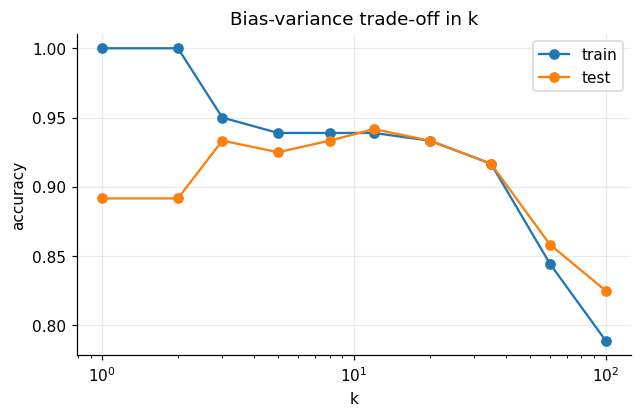

In [4]:
ks = [1, 2, 3, 5, 8, 12, 20, 35, 60, 100]
tr = [(KNNClassifier(k=k).fit(Xtr, ytr).predict(Xtr) == ytr).mean() for k in ks]
te = [(KNNClassifier(k=k).fit(Xtr, ytr).predict(Xte) == yte).mean() for k in ks]
plt.figure(figsize=(6.5, 3.8)); plt.semilogx(ks, tr, "o-", label="train"); plt.semilogx(ks, te, "o-", label="test")
plt.xlabel("k"); plt.ylabel("accuracy"); plt.legend(); plt.title("Bias-variance trade-off in k"); plt.show()

### 3. Scale matters: distance is everything

kNN uses raw Euclidean distance, so a feature measured in big units drowns out the others. Same data, one informative feature and one noise feature: multiply the noise feature's scale by 1000 and accuracy collapses to chance, because the neighbours are now chosen almost only by noise. Standardise first.

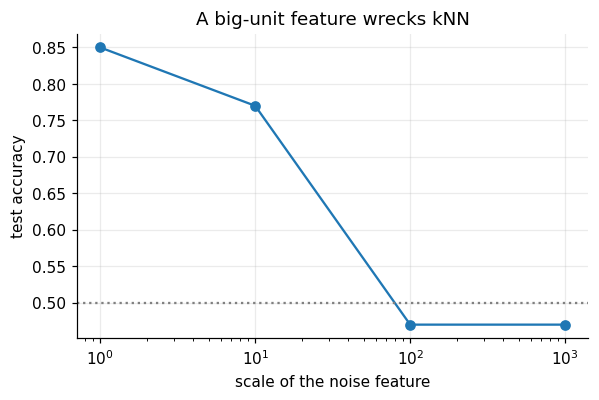

In [5]:
rng = np.random.default_rng(1)
n = 300; y3 = rng.integers(0, 2, n)
signal = y3 + rng.normal(scale=0.5, size=n); noise = rng.normal(size=n)
tr_idx, te_idx = np.arange(n) < 200, np.arange(n) >= 200
res = {}
for scale in (1, 10, 100, 1000):
    Xs = np.c_[signal, noise * scale]
    res[scale] = (KNNClassifier(k=5).fit(Xs[tr_idx], y3[tr_idx]).predict(Xs[te_idx]) == y3[te_idx]).mean()
plt.figure(figsize=(6, 3.6)); plt.semilogx(list(res), list(res.values()), "o-"); plt.axhline(0.5, color="gray", ls=":")
plt.xlabel("scale of the noise feature"); plt.ylabel("test accuracy"); plt.title("A big-unit feature wrecks kNN"); plt.show()

## Check against a reference implementation

Same data, same settings as scikit-learn (or scipy / the real library). The assertions fail if the two disagree.

In [6]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier as SklearnKNN

data = load_iris()
X_train, X_test, y_train, y_test = train_test_split(
    data.data, data.target, test_size=0.3, random_state=42
)

ours = KNNClassifier(k=5).fit(X_train, y_train)
theirs = SklearnKNN(n_neighbors=5).fit(X_train, y_train)

acc_ours = (ours.predict(X_test) == y_test).mean()
acc_theirs = (theirs.predict(X_test) == y_test).mean()
print("iris test accuracy: ours=%.4f sklearn=%.4f" % (acc_ours, acc_theirs))
assert acc_ours == acc_theirs, "brute-force euclidean KNN should match sklearn exactly here"

iris test accuracy: ours=1.0000 sklearn=1.0000


## Tests

Plain `assert` tests that check the invariants of the algorithm.

In [7]:
import numpy as np


def test_simple_separated_clusters():
    X_train = np.array([[0, 0], [0, 1], [1, 0], [10, 10], [10, 11], [11, 10]])
    y_train = np.array([0, 0, 0, 1, 1, 1])
    model = KNNClassifier(k=3).fit(X_train, y_train)

    preds = model.predict(np.array([[0.5, 0.5], [10.5, 10.5]]))
    assert list(preds) == [0, 1]


def test_iris_like_accuracy():
    from sklearn.datasets import load_iris
    from sklearn.model_selection import train_test_split

    data = load_iris()
    X_train, X_test, y_train, y_test = train_test_split(
        data.data, data.target, test_size=0.3, random_state=0
    )
    model = KNNClassifier(k=5).fit(X_train, y_train)
    preds = model.predict(X_test)
    accuracy = (preds == y_test).mean()
    assert accuracy > 0.9, accuracy

In [8]:
tests = [(name, fn) for name, fn in list(globals().items()) if name.startswith("test_") and callable(fn)]
for name, fn in tests:
    fn()
    print("PASS", name)
print(f"\nall {len(tests)} tests passed")

PASS test_simple_separated_clusters
PASS test_iris_like_accuracy

all 2 tests passed


## Takeaways

- **Use it when** you have little data and a meaningful distance; it is a great quick baseline and needs no training.
- **Cost:** `fit` is free, `predict` is `O(n·d)` per query (this brute-force version). Real implementations use KD-trees / ball trees or approximate search.
- **Pitfalls:** feature scaling (section 3), irrelevant features (they dilute distance), the curse of dimensionality (in high `d` all points are nearly equidistant), imbalanced classes (the majority wins votes).
- **Interview line:** *"Lazy learner: store everything, vote among the `k` nearest. Small `k` = high variance, large `k` = high bias. Scale your features."*